# 12 — Subject-level uncertainty calibration

**Research question:** Khoảng dự đoán có đạt mức bao phủ danh nghĩa trên các test chưa tham gia calibration mới không?

Baseline: absolute-residual split conformal, nominal 90%; max qua ảnh/người, thêm joint max qua ba target. Calibration tách khỏi toàn bộ fit/normalization/BN/epoch selection mới.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Module_01_User_and_Body_Profile.md").exists())
for path in [ROOT, ROOT / "scripts"]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
import numpy as np
from IPython.display import display, Markdown
report = json.loads((ROOT / "experiments/bodym_phase3/metrics.json").read_text(encoding="utf-8"))


In [2]:
import math
for name, result in report["results"].items():
    cal = result["calibrator"]
    assert cal["order_statistic_rank"] == math.ceil((cal["calibration_subjects"] + 1) * (1 - cal["alpha"]))
    assert cal["checkpoint_sha256"] == result["checkpoint_sha256"]
    print(name, "n=", cal["calibration_subjects"], "rank=", cal["order_statistic_rank"],
          "radii=", cal["per_target_radius_cm"], "joint radius=", cal["joint_radius_cm"])

tabular_only n= 323 rank= 292 radii= {'chest': 5.945082832032995, 'waist': 7.549388800263841, 'hip': 4.657891936382839} joint radius= 8.041511604811603
image_only n= 323 rank= 292 radii= {'chest': 9.975985490575681, 'waist': 11.554571379506342, 'hip': 9.732431407583931} joint radius= 12.65209352730676
fusion n= 323 rank= 292 radii= {'chest': 5.617867808822666, 'waist': 6.161803852357593, 'hip': 4.26733540610951} joint radius= 7.432083656995019


In [3]:
from src.multimodal.calibration import interval_metrics
rows = ["| Variant | Test | Joint all-photo subject coverage | Joint full width (cm) |", "|---|---|---:|---:|"]
for name, result in report["results"].items():
    for test in ["testA", "testB"]:
        with np.load(ROOT / f"data/processed/bodym_phase3/{name}/{test}_predictions.npz") as data:
            actual = interval_metrics(data["y"], data["prediction"], data["subject_ids"], result["calibrator"])
        assert actual == result["tests"][test]["interval"]
        rows.append(f"| {name} | {test} | {actual['joint_subject_all_targets_all_photos_coverage']:.1%} | {actual['joint_width_cm']:.3f} |")
display(Markdown("\n".join(rows)))

| Variant | Test | Joint all-photo subject coverage | Joint full width (cm) |
|---|---|---:|---:|
| tabular_only | testA | 93.1% | 16.083 |
| tabular_only | testB | 87.5% | 16.083 |
| image_only | testA | 85.1% | 25.304 |
| image_only | testB | 76.8% | 25.304 |
| fusion | testA | 88.5% | 14.864 |
| fusion | testB | 81.0% | 14.864 |

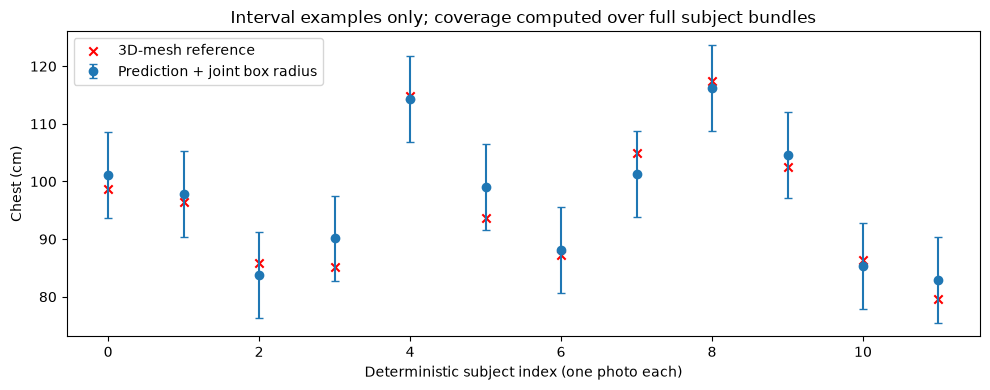

In [4]:
import matplotlib.pyplot as plt
name, test = "fusion", "testB"
with np.load(ROOT / f"data/processed/bodym_phase3/{name}/{test}_predictions.npz") as data:
    _, first = np.unique(data["subject_ids"], return_index=True)
    index = first[:12]  # Deterministic first 12 subjects, not selected by errors.
    pred, truth = data["prediction"][index, 0], data["y"][index, 0]
radius = report["results"][name]["calibrator"]["joint_radius_cm"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(np.arange(len(index)), pred, yerr=radius, fmt="o", capsize=3, label="Prediction + joint box radius")
ax.scatter(np.arange(len(index)), truth, marker="x", color="red", label="3D-mesh reference")
ax.set_xlabel("Deterministic subject index (one photo each)"); ax.set_ylabel("Chest (cm)")
ax.set_title("Interval examples only; coverage computed over full subject bundles")
ax.legend(); fig.tight_layout(); plt.show()

## Error analysis / conclusion

Báo độ bao phủ từng target, joint, width và subject-balanced pair coverage riêng. Một ảnh vượt khoảng khiến all-photo subject coverage thất bại. TestA có nhiều ảnh/người hơn calibration nên max-error distribution có thể đổi; testB cũng khác capture domain.

Không biến mức danh nghĩa 90% thành xác suất đúng cho một cá nhân, không khẳng định bảo đảm khi exchangeability/predictor independence không thỏa. Pipeline từng dùng dữ liệu này trước đây; cần đánh giá prospective mới. Không gắn calibrator vào default đã học mọi người train. Tham khảo [Angelopoulos & Bates](https://arxiv.org/abs/2107.07511).